In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
from pathlib import Path
sns.set_style("whitegrid")

project_root = Path.cwd().resolve()
if not (project_root / "datasets").exists():
    project_root = project_root.parent
DATA_DIR = project_root / "datasets"
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv(DATA_DIR / "ai_trust_by_country.csv")
df2 = pd.read_csv(DATA_DIR / "ai_benefit_perception_trend.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'datasets/ai_trust_by_country.csv'

In [29]:
datasets = {
    "Trust": df,
    "Benefit": df2
}

for name, data in datasets.items():
    print("=" * 70)
    print(f"{name} Dataset")
    print("=" * 70)

    print(f"Shape: {data.shape}")
    print("\nColumns:")
    print(data.columns.tolist())

    print("\nData Types:")
    print(data.dtypes)

    print("\nFirst Five Rows:")
    display(data.head())

    print("\n")

Trust Dataset
Shape: (47, 43)

Columns:
['country', 'iso3', 'region', 'economy_type', 'gdp_per_capita_usd', 'population', 'sentiment', 'regulation_required_pct', 'aware_regulations_pct', 'safeguards_sufficient_pct', 'unsure_online_content_pct', 'concerned_elections_pct', 'want_misinfo_laws_pct', 'trust_ai_pct', 'accept_ai_pct', 'expect_benefits_pct', 'experienced_benefits_pct', 'top_benefit_pct', 'risks_outweigh_benefits_pct', 'concerned_negative_pct', 'experienced_negative_pct', 'top_risk_pct', 'literacy_skills_pct', 'ai_training_pct', 'use_ai_effectively_pct', 'org_uses_ai_pct', 'use_ai_work_regularly_pct', 'relied_not_learning_pct', 'concerned_left_behind_pct', 'couldnt_work_without_ai_pct', 'inappropriate_use_pct', 'mistakes_due_ai_pct', 'contravene_policies_pct', 'relied_no_eval_pct', 'presented_ai_as_own_pct', 'org_ai_strategy_pct', 'org_provides_training_pct', 'org_ai_policies_pct', 'work_performable_by_ai_pct', 'ai_raised_compliance_risk_pct', 'increased_efficiency_pct', 'incre

,country,iso3,region,economy_type,gdp_per_capita_usd,population,sentiment,regulation_required_pct,aware_regulations_pct,safeguards_sufficient_pct,...,relied_no_eval_pct,presented_ai_as_own_pct,org_ai_strategy_pct,org_provides_training_pct,org_ai_policies_pct,work_performable_by_ai_pct,ai_raised_compliance_risk_pct,increased_efficiency_pct,increased_revenue_pct,increased_workload_pct
0,Argentina,ARG,Latin America & Caribbean,emerging,14898,45851378,optimistic,71,13,39,...,68,49,54,58,50,51,30,60,41,22
1,Australia,AUS,Oceania,advanced,65130,27614411,worried,77,10,30,...,57,51,59,55,56,39,30,50,40,22
2,Austria,AUT,Northern & Western Europe,advanced,62930,9208163,mixed,66,14,39,...,62,54,48,47,45,38,27,45,39,21
3,Belgium,BEL,Northern & Western Europe,advanced,60750,11941781,worried,72,10,34,...,66,61,53,53,53,40,38,53,40,31
4,Brazil,BRA,Latin America & Caribbean,emerging,10713,212812405,mixed,66,19,54,...,69,51,75,67,68,48,34,71,55,27




Benefit Dataset
Shape: (32, 6)

Columns:
['country', 'iso3', 'benefit_gt_drawback_2023_pct', 'benefit_gt_drawback_2024_pct', 'change_2023_2024_pp', 'in_country_trust_dataset']

Data Types:
country                          object
iso3                             object
benefit_gt_drawback_2023_pct    float64
benefit_gt_drawback_2024_pct      int64
change_2023_2024_pp             float64
in_country_trust_dataset           bool
dtype: object

First Five Rows:


,country,iso3,benefit_gt_drawback_2023_pct,benefit_gt_drawback_2024_pct,change_2023_2024_pp,in_country_trust_dataset
0,China,CHN,NaN,83,NaN,True
1,Indonesia,IDN,78.0,80,2.0,False
2,Thailand,THA,74.0,77,3.0,False
3,Peru,PER,67.0,70,3.0,False
4,Mexico,MEX,73.0,70,-3.0,True


In [30]:
summary = []

for name, data in datasets.items():

    summary.append({
        "Dataset": name,
        "Rows": data.shape[0],
        "Columns": data.shape[1],
        "Missing Values": data.isnull().sum().sum(),
        "Duplicate Rows": data.duplicated().sum()
    })

summary_data = pd.DataFrame(summary)

summary_data

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,Trust,47,43,0,0
1,Benefit,32,6,4,0


In [31]:
# ============================================================
# Missing Value Analysis
# ============================================================

for name, data in datasets.items():

    print("="*70)
    print(f"{name} Dataset")
    print("="*70)

    missing = pd.DataFrame({
        "Missing Count": data.isnull().sum(),
        "Missing Percentage": round(data.isnull().mean()*100,2)
    })

    missing = missing[missing["Missing Count"]>0].sort_values(
        by="Missing Count",
        ascending=False
    )

    if missing.empty:
        print("No missing values.\n")
    else:
        display(missing)

Trust Dataset
No missing values.

Benefit Dataset


,Missing Count,Missing Percentage
benefit_gt_drawback_2023_pct,2,6.25
change_2023_2024_pp,2,6.25


Findings: 
- Change_2023_2024 has two missing values since two countries (China and Switzerland) have no 2023 values.
- On the other hand, Indonesia, Thailand, Peru, Malaysia have complete values, however said 4 countries do not have data points in the Trust dataset. 


## First Dataset - Trust

### Q1 Which countries have the highest and lowest AI trust?

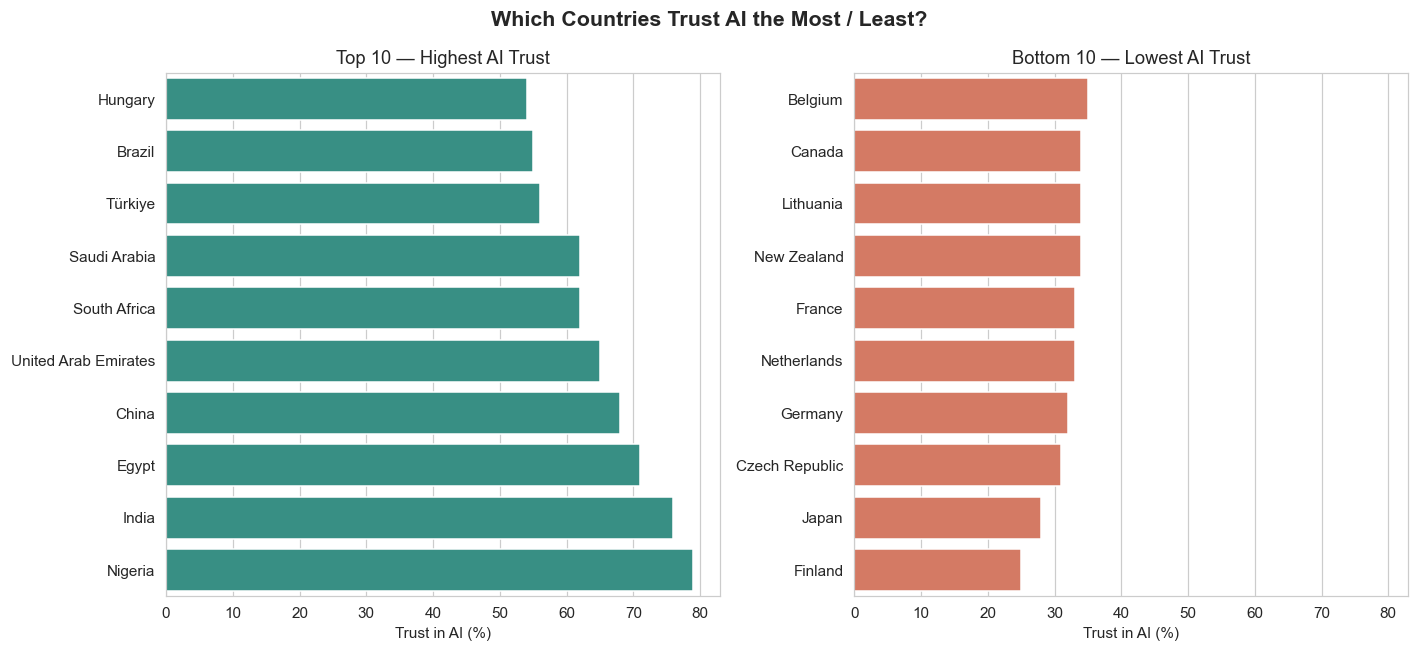

In [32]:
# ==================================================================
# Q1 Which countries have the highest and lowest AI trust?
# ==================================================================
top_n = 10
top = df.nlargest(top_n, "trust_ai_pct")[["country", "trust_ai_pct"]]
bottom = df.nsmallest(top_n, "trust_ai_pct")[["country", "trust_ai_pct"]]

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True)

sns.barplot(data=top.sort_values("trust_ai_pct"), y="country", x="trust_ai_pct",
            ax=axes[0], color="#2a9d8f")
axes[0].set_title(f"Top {top_n} — Highest AI Trust")
axes[0].set_xlabel("Trust in AI (%)")
axes[0].set_ylabel("")

sns.barplot(data=bottom.sort_values("trust_ai_pct", ascending=False), y="country", x="trust_ai_pct",
            ax=axes[1], color="#e76f51")
axes[1].set_title(f"Bottom {top_n} — Lowest AI Trust")
axes[1].set_xlabel("Trust in AI (%)")
axes[1].set_ylabel("")

plt.suptitle("Which Countries Trust AI the Most / Least?", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


FIndings:
- Nigeria (79%) and India (76%) has the highest trust in AI
- Finland (25%) and Japan (28%) are lowest, roughly a 50% gap.

### Q2 Do emerging vs advanced economies they trust AI differently?

C:\Users\welth\AppData\Local\Temp\ipykernel_62664\738703065.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="economy_type", y="trust_ai_pct", ax=axes[0],


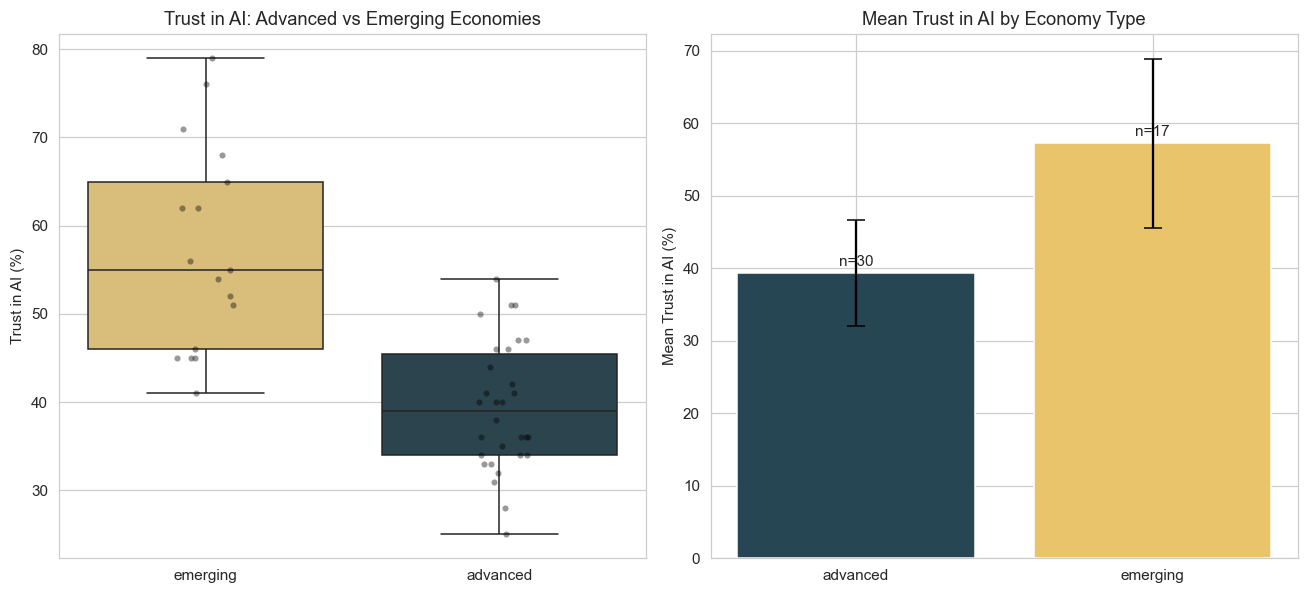

In [33]:
# ==================================================================
# Q2 Emerging vs advanced economies — do they trust AI differently?
# ==================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

# Boxplot: distribution comparison
sns.boxplot(data=df, x="economy_type", y="trust_ai_pct", ax=axes[0],
            palette={"advanced": "#264653", "emerging": "#e9c46a"})
sns.stripplot(data=df, x="economy_type", y="trust_ai_pct", ax=axes[0],
              color="black", alpha=0.4, size=4, jitter=True)
axes[0].set_title("Trust in AI: Advanced vs Emerging Economies")
axes[0].set_xlabel("")
axes[0].set_ylabel("Trust in AI (%)")

# Mean comparison bar with error bars
summary = df.groupby("economy_type")["trust_ai_pct"].agg(["mean", "std", "count"]).reset_index()
axes[1].bar(summary["economy_type"], summary["mean"],
            yerr=summary["std"], capsize=6,
            color=["#264653", "#e9c46a"])
axes[1].set_title("Mean Trust in AI by Economy Type")
axes[1].set_ylabel("Mean Trust in AI (%)")
for i, row in summary.iterrows():
    axes[1].text(i, row["mean"] + 1, f"n={row['count']}", ha="center")

plt.tight_layout()
plt.show()


In [34]:
# Print summary stats + a quick significance check (Mann-Whitney U, robust for small n)
from scipy.stats import mannwhitneyu
adv = df.loc[df.economy_type == "advanced", "trust_ai_pct"]
eme = df.loc[df.economy_type == "emerging", "trust_ai_pct"]
u_stat, p_val = mannwhitneyu(adv, eme, alternative="two-sided")
 
print("=== Q2: Economy type summary ===")
print(summary)
print(f"Mann-Whitney U test: U={u_stat:.1f}, p={p_val:.4f}")
print()
 

=== Q2: Economy type summary ===
  economy_type       mean        std  count
0     advanced  39.366667   7.265807     30
1     emerging  57.235294  11.616418     17
Mann-Whitney U test: U=45.5, p=0.0000



Findings:
- Emerging economies average 57.2% trust vs. advanced economies at 39.4%, a clear and statistically significant gap (Mann-Whitney U test, p < 0.001, despite the small n=47). 
- Emerging economies consistently trust AI more.

### Q3 Is there regional differences?

C:\Users\welth\AppData\Local\Temp\ipykernel_62664\1852100845.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="trust_ai_pct", y="region", order=region_order,


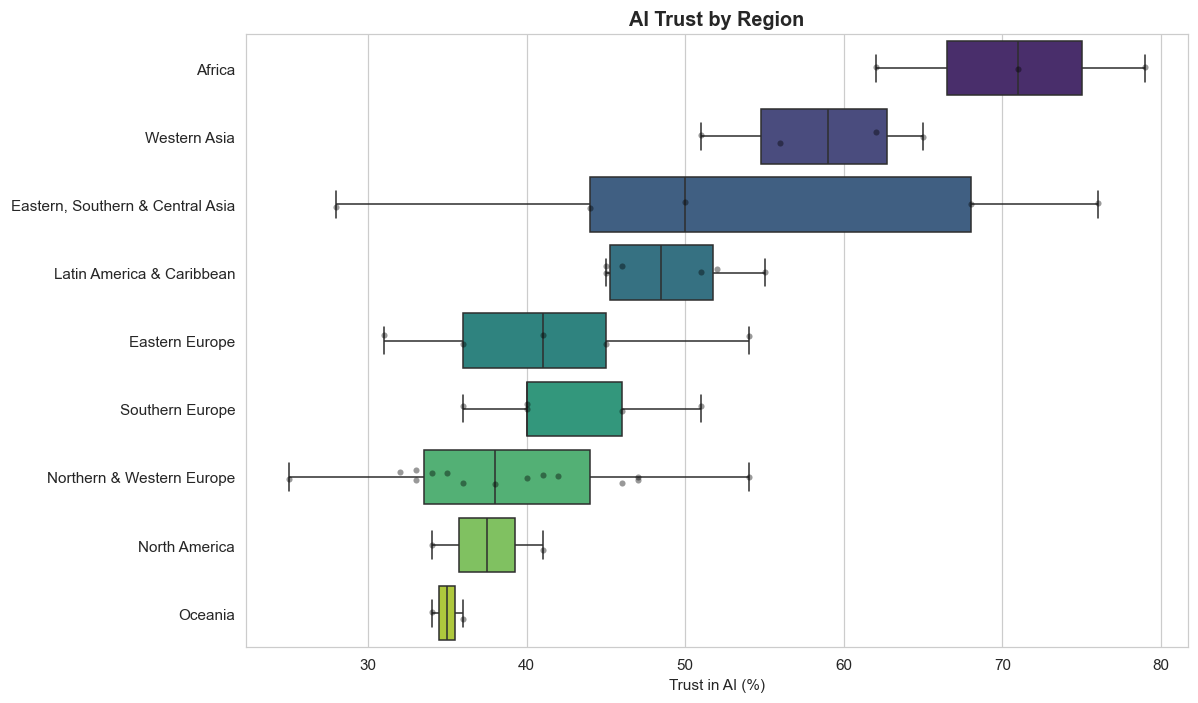

In [35]:
# ==================================================================
# Q3: Regional differences
# ==================================================================
region_order = df.groupby("region")["trust_ai_pct"].median().sort_values(ascending=False).index
 
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.boxplot(data=df, x="trust_ai_pct", y="region", order=region_order,
            palette="viridis", ax=ax)
sns.stripplot(data=df, x="trust_ai_pct", y="region", order=region_order,
              color="black", alpha=0.4, size=4, ax=ax)
ax.set_title("AI Trust by Region", fontsize=13, fontweight="bold")
ax.set_xlabel("Trust in AI (%)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [36]:
region_summary = df.groupby("region")["trust_ai_pct"].agg(["mean", "median", "std", "count"]).sort_values("mean", ascending=False)
print("=== Q3: Regional summary ===")
print(region_summary)
print()
 

=== Q3: Regional summary ===
                                       mean  median        std  count
region                                                               
Africa                            70.666667    71.0   8.504901      3
Western Asia                      58.500000    59.0   6.244998      4
Eastern, Southern & Central Asia  53.200000    50.0  19.162463      5
Latin America & Caribbean         49.000000    48.5   4.242641      6
Southern Europe                   42.600000    40.0   5.899152      5
Eastern Europe                    41.400000    41.0   8.792042      5
Northern & Western Europe         38.866667    38.0   7.482042     15
North America                     37.500000    37.5   4.949747      2
Oceania                           35.000000    35.0   1.414214      2



Findings:
- Africa (71% mean) and Western Asia (58%) trust AI most
- Oceania (35%), North America (38%), and Northern & Western Europe (39%) trust it least
- Note Eastern/Southern/Central Asia has a huge spread (28–76%), so sum ting wong

### Q4 Correlation Heatmap

In [37]:
pct_cols = [c for c in df.columns if c.endswith("_pct")]

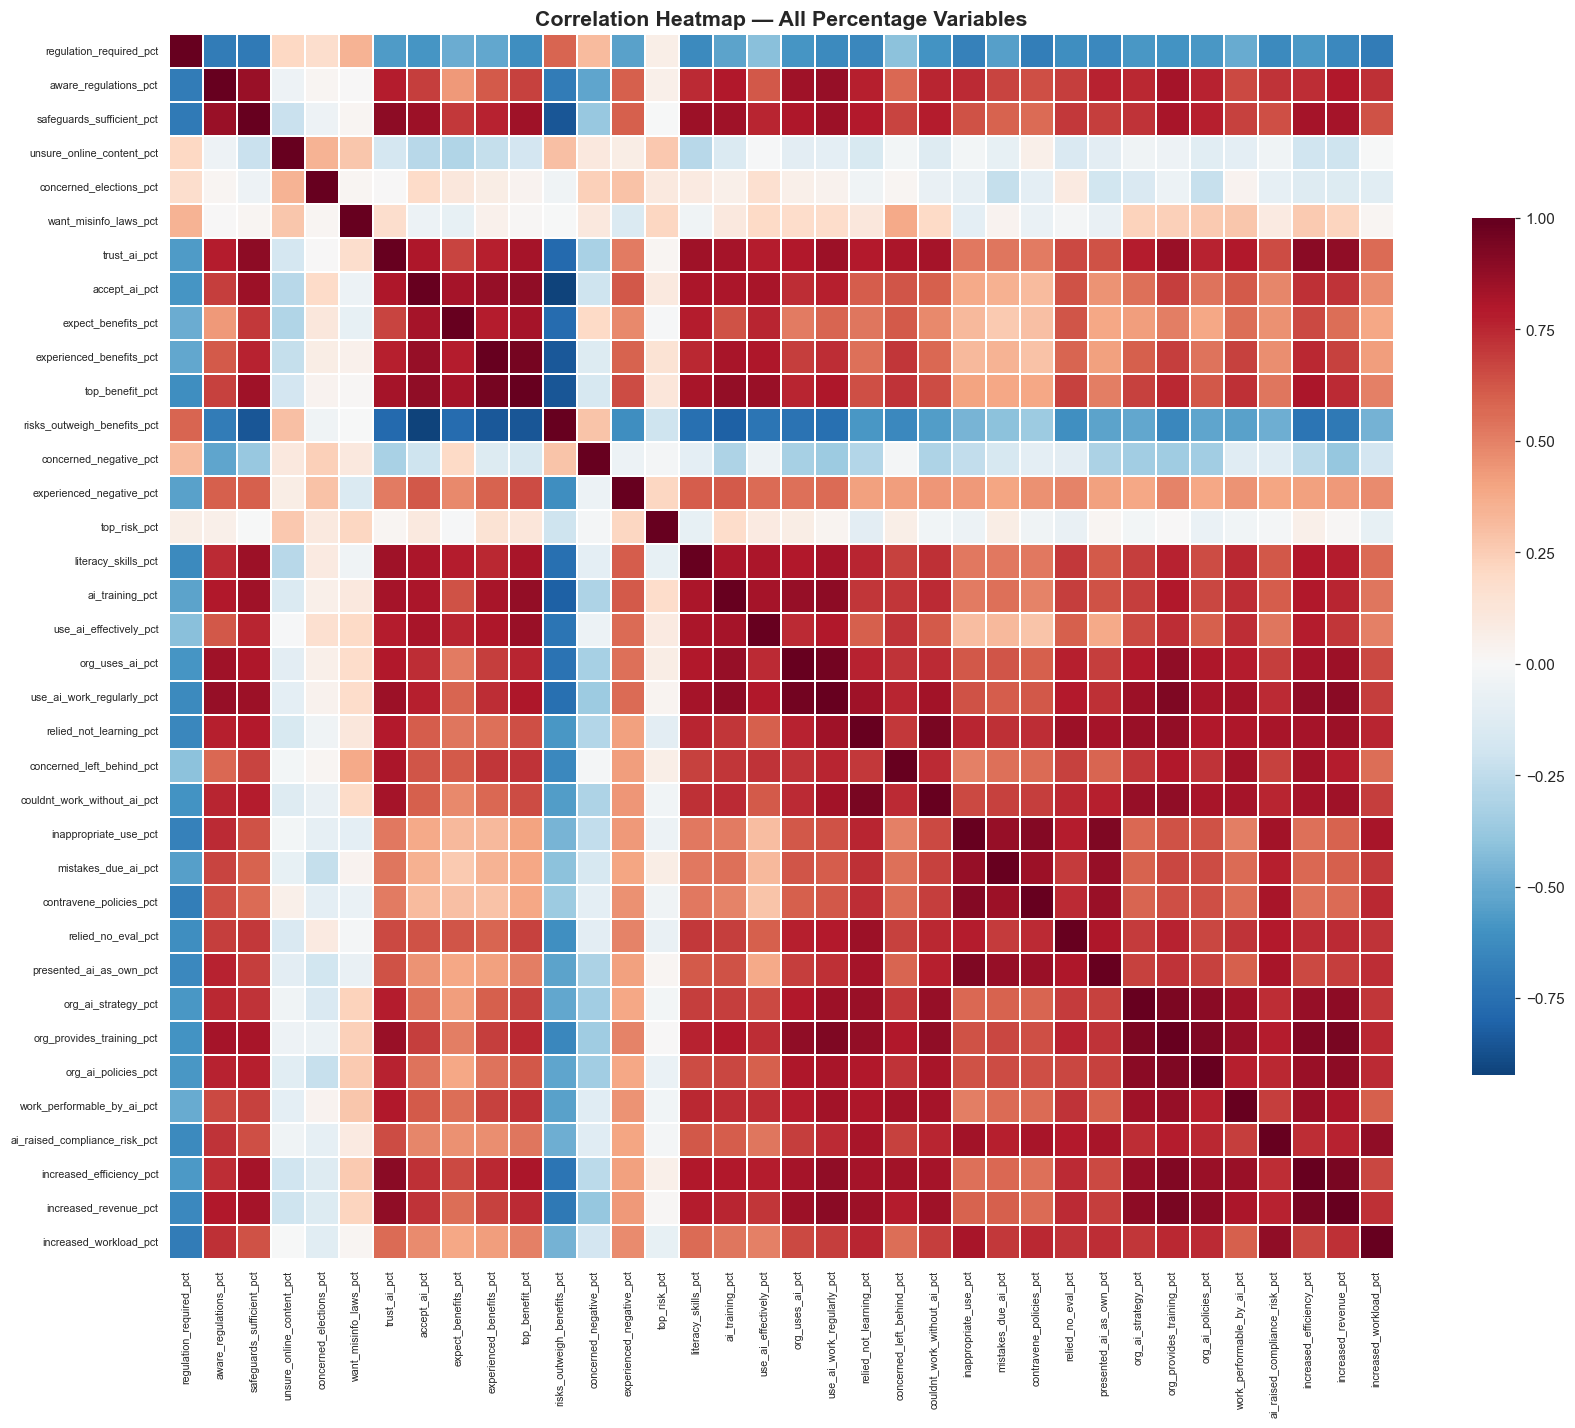

=== Strongest correlations with trust_ai_pct ===
increased_efficiency_pct       0.896179
safeguards_sufficient_pct      0.893507
increased_revenue_pct          0.887176
org_provides_training_pct      0.860513
use_ai_work_regularly_pct      0.852725
literacy_skills_pct            0.847116
ai_training_pct                0.832348
couldnt_work_without_ai_pct    0.830640
Name: trust_ai_pct, dtype: float64
...
contravene_policies_pct        0.511872
want_misinfo_laws_pct          0.175487
top_risk_pct                   0.020943
concerned_elections_pct        0.008070
unsure_online_content_pct     -0.177777
concerned_negative_pct        -0.324172
regulation_required_pct       -0.566008
risks_outweigh_benefits_pct   -0.780150
Name: trust_ai_pct, dtype: float64



In [38]:

# ==================================================================
# Q4 Correlation heatmap
# ==================================================================
corr = df[pct_cols].corr()

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=False,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlation Heatmap — All Percentage Variables", fontsize=14, fontweight="bold")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()

# Print top correlations with trust_ai_pct specifically
trust_corr = corr["trust_ai_pct"].drop("trust_ai_pct").sort_values(ascending=False)
print("=== Strongest correlations with trust_ai_pct ===")
print(trust_corr.head(8))
print("...")
print(trust_corr.tail(8))
print()


FIndings:
- nearly everything is positively correlated with everything else, except a small cluster of variables
- countries with generally positive dispositions score high on almost everything
- aw man, these variables may be dependent

### Test: Multicolinearity and Independence

=== (a) VIF: candidate predictor set ===
                  feature  VIF
safeguards_sufficient_pct 8.50
          ai_training_pct 7.47
          org_uses_ai_pct 7.21
    aware_regulations_pct 7.14
      literacy_skills_pct 5.92
 increased_efficiency_pct 4.69
 experienced_benefits_pct 3.89
   concerned_negative_pct 2.02
Rule of thumb: VIF > 5 moderate, > 10 severe multicollinearity

=== (b) Iterative VIF pruning (threshold = 10) ===
Started with 35 columns -> kept 19
Dropped (in order):
  top_benefit_pct                     VIF at drop = 178.9
  inappropriate_use_pct               VIF at drop = 131.4
  use_ai_work_regularly_pct           VIF at drop = 86.0
  accept_ai_pct                       VIF at drop = 82.8
  org_provides_training_pct           VIF at drop = 75.3
  relied_not_learning_pct             VIF at drop = 44.2
  increased_revenue_pct               VIF at drop = 37.5
  expect_benefits_pct                 VIF at drop = 31.5
  safeguards_sufficient_pct           VIF at drop = 

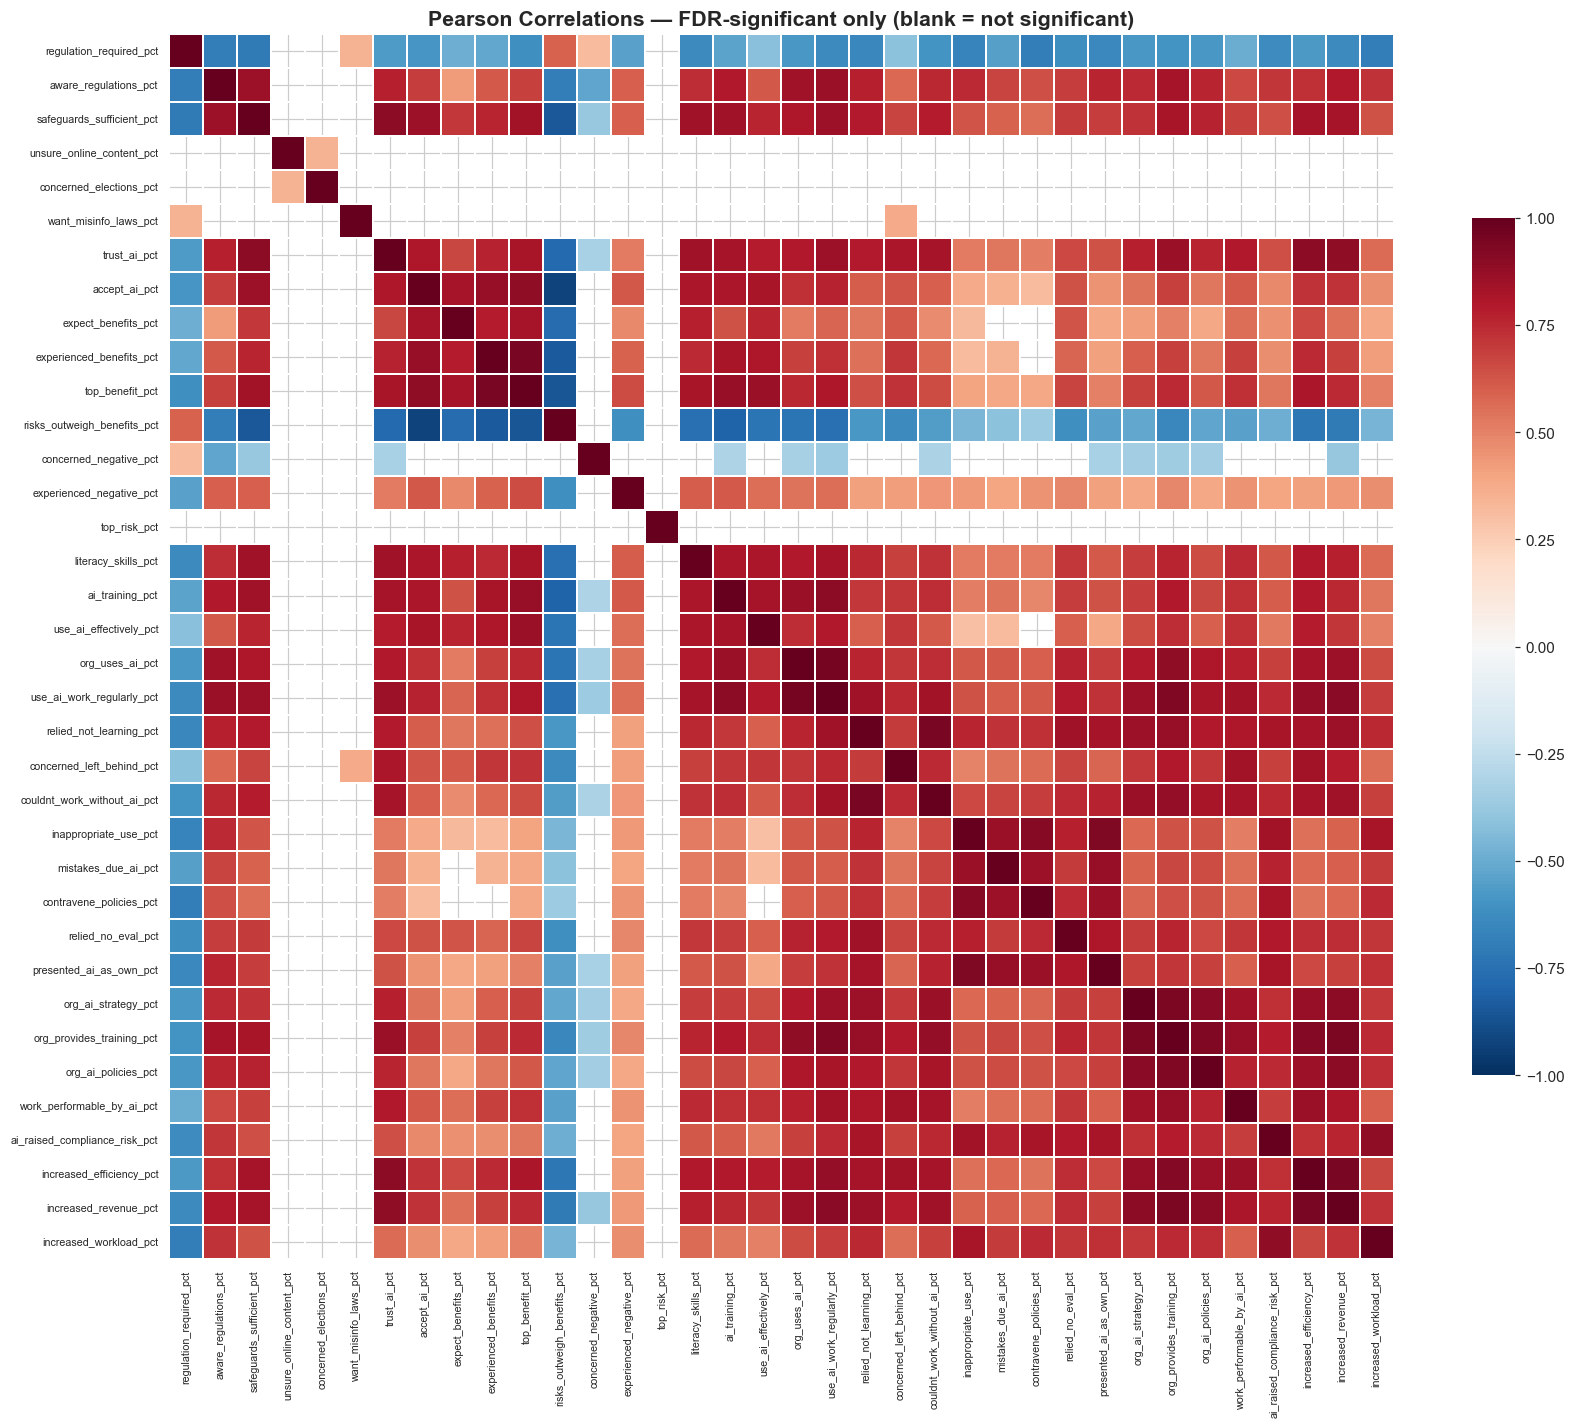

In [39]:
# ==================================================================
# A little advertisement, I'm running dependence and multicolinearity test
# ==================================================================

from itertools import combinations
from scipy import stats

# ------------------------------------------------------------------
# 1. VIF
# ------------------------------------------------------------------
# With ~43 pct columns and n=47, running VIF on ALL columns is
# meaningless (p ~ n, so VIFs explode to inf). So we do two things:
#   (a) VIF on a theory-driven candidate predictor set
#   (b) iterative pruning of the full set until all VIF < threshold

def compute_vif(X: pd.DataFrame) -> pd.DataFrame:
    # VIF_j = 1 / (1 - R^2_j), where R^2_j comes from regressing column j on the others
    A = X.astype(float).values
    vifs = []
    for j in range(A.shape[1]):
        y = A[:, j]
        Z = np.column_stack([np.ones(len(A)), np.delete(A, j, axis=1)])
        beta, *_ = np.linalg.lstsq(Z, y, rcond=None)
        ss_res = ((y - Z @ beta) ** 2).sum()
        ss_tot = ((y - y.mean()) ** 2).sum()
        r2 = 1 - ss_res / ss_tot
        vifs.append(np.inf if r2 >= 1 - 1e-12 else 1 / (1 - r2))
    return (pd.DataFrame({"feature": X.columns, "VIF": vifs})
              .sort_values("VIF", ascending=False).reset_index(drop=True))

# (a) Candidate predictors for a trust regression -- edit to taste
candidate_predictors = [
    "aware_regulations_pct", "safeguards_sufficient_pct", "literacy_skills_pct",
    "ai_training_pct", "org_uses_ai_pct", "experienced_benefits_pct",
    "concerned_negative_pct", "increased_efficiency_pct",
]
candidate_predictors = [c for c in candidate_predictors if c in df.columns]

vif_candidate = compute_vif(df[candidate_predictors].dropna())
print("=== (a) VIF: candidate predictor set ===")
print(vif_candidate.round(2).to_string(index=False))
print("Rule of thumb: VIF > 5 moderate, > 10 severe multicollinearity\n")

# (b) Iterative pruning: drop the highest-VIF column until all < threshold
def prune_by_vif(X: pd.DataFrame, threshold: float = 10.0, protect=()):
    X = X.copy()
    dropped = []
    while X.shape[1] > 2:
        v = compute_vif(X)
        v = v[~v["feature"].isin(protect)]
        if v.empty or v["VIF"].iloc[0] < threshold:
            break
        worst = v.iloc[0]
        dropped.append((worst["feature"], worst["VIF"]))
        X = X.drop(columns=worst["feature"])
    return X, dropped

target = "trust_ai_pct"
X_all = df[[c for c in pct_cols if c != target]].dropna()
X_pruned, dropped = prune_by_vif(X_all, threshold=10.0)

print("=== (b) Iterative VIF pruning (threshold = 10) ===")
print(f"Started with {X_all.shape[1]} columns -> kept {X_pruned.shape[1]}")
print("Dropped (in order):")
for name, val in dropped:
    print(f"  {name:35s} VIF at drop = {val:,.1f}")
print("\nRemaining VIFs:")
print(compute_vif(X_pruned).round(2).to_string(index=False))

# Condition number of the full standardized matrix (overall collinearity check)
Z = (X_all - X_all.mean()) / X_all.std()
print(f"\nCondition number (all columns, standardized): {np.linalg.cond(Z.values):,.1f}  (>30 = concern)\n")

# ------------------------------------------------------------------
# 2. Chi-square test of independence (categorical pairs)
# ------------------------------------------------------------------
# With n=47 and up to ~9 regions, many expected counts will be < 5, which
# violates the chi-square assumption. So we report:
#   - classic chi-square p-value
#   - % of cells with expected count < 5
#   - Monte Carlo permutation p-value (valid for small n)
#   - bias-corrected Cramer's V (effect size)

def cramers_v_corrected(ct: pd.DataFrame) -> float:
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    r, k = ct.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rcorr = r - (r - 1) ** 2 / (n - 1)
    kcorr = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(1e-12, min(kcorr - 1, rcorr - 1)))

def chi2_with_permutation(a: pd.Series, b: pd.Series, n_perm=10_000, seed=42):
    ct = pd.crosstab(a, b)
    chi2, p, dof, expected = stats.chi2_contingency(ct, correction=False)
    pct_low = (expected < 5).mean() * 100
    rng = np.random.default_rng(seed)
    a_vals, b_vals = a.values, b.values
    count = 0
    for _ in range(n_perm):
        perm = rng.permutation(b_vals)
        c2 = stats.chi2_contingency(pd.crosstab(a_vals, perm), correction=False)[0]
        count += c2 >= chi2 - 1e-12
    p_perm = (count + 1) / (n_perm + 1)
    return {"chi2": chi2, "dof": dof, "p_chi2": p, "pct_cells_exp<5": pct_low,
            "p_permutation": p_perm, "cramers_V": cramers_v_corrected(ct)}, ct

cat_pairs = [("region", "economy_type"),
             ("sentiment", "economy_type"),
             ("region", "sentiment")]

rows = []
for a, b in cat_pairs:
    res, ct = chi2_with_permutation(df[a], df[b])
    res["pair"] = f"{a} vs {b}"
    rows.append(res)
    print(f"--- Contingency table: {a} x {b} ---")
    print(ct, "\n")

chi_table = pd.DataFrame(rows).set_index("pair")[
    ["chi2", "dof", "p_chi2", "pct_cells_exp<5", "p_permutation", "cramers_V"]]
print("=== Chi-square tests of independence ===")
print(chi_table.round(4))
print("Trust p_permutation over p_chi2 whenever pct_cells_exp<5 is high.\n")

# ------------------------------------------------------------------
# 3. Correlation significance (Pearson + Spearman, with FDR correction)
# ------------------------------------------------------------------
# 43 columns -> ~900 pairwise tests, so raw p < 0.05 would give ~45 false
# positives by chance alone. We apply Benjamini-Hochberg FDR correction.

def corr_pvalues(data: pd.DataFrame, method="pearson") -> pd.DataFrame:
    rows = []
    for a, b in combinations(data.columns, 2):
        sub = data[[a, b]].dropna()
        if method == "pearson":
            r, p = stats.pearsonr(sub[a], sub[b])
        else:
            r, p = stats.spearmanr(sub[a], sub[b])
        rows.append((a, b, r, p, len(sub)))
    out = pd.DataFrame(rows, columns=["var1", "var2", "r", "p", "n"])
    out["p_fdr"] = stats.false_discovery_control(out["p"].values, method="bh")
    out["sig_fdr_0.05"] = out["p_fdr"] < 0.05
    return out

pear = corr_pvalues(df[pct_cols], "pearson")
spear = corr_pvalues(df[pct_cols], "spearman")

n_pairs = len(pear)
print(f"=== Pairwise correlation significance ({n_pairs} pairs, n={len(df)}) ===")
print(f"Pearson : {(pear.p < 0.05).sum()} sig. raw | {pear['sig_fdr_0.05'].sum()} sig. after FDR")
print(f"Spearman: {(spear.p < 0.05).sum()} sig. raw | {spear['sig_fdr_0.05'].sum()} sig. after FDR\n")

# Focus: every variable vs trust_ai_pct
def vs_target(res, target):
    m = res[(res.var1 == target) | (res.var2 == target)].copy()
    m["variable"] = np.where(m.var1 == target, m.var2, m.var1)
    return m[["variable", "r", "p", "p_fdr", "sig_fdr_0.05"]]

trust_p = (vs_target(pear, target).merge(
              vs_target(spear, target), on="variable", suffixes=("_pearson", "_spearman"))
           .sort_values("r_pearson", ascending=False))
print(f"=== Correlations with {target} ===")
print(trust_p.round(4).to_string(index=False))

# Agreement check: Pearson vs Spearman disagreements hint at outliers/non-linearity
disagree = trust_p[trust_p["sig_fdr_0.05_pearson"] != trust_p["sig_fdr_0.05_spearman"]]
print(f"\nVariables where Pearson and Spearman disagree on significance: {len(disagree)}")
print(disagree[["variable", "r_pearson", "r_spearman"]].round(3).to_string(index=False))

# Heatmap: only FDR-significant Pearson correlations shown
r_mat = df[pct_cols].corr()
sig_arr = np.eye(len(pct_cols), dtype=bool)
idx = {c: i for i, c in enumerate(pct_cols)}
for _, row in pear[pear["sig_fdr_0.05"]].iterrows():
    sig_arr[idx[row.var1], idx[row.var2]] = True
    sig_arr[idx[row.var2], idx[row.var1]] = True
sig_mask = pd.DataFrame(sig_arr, index=pct_cols, columns=pct_cols)

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(r_mat.where(sig_mask), cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Pearson Correlations — FDR-significant only (blank = not significant)",
             fontsize=14, fontweight="bold")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()

Findings???
- Chi Square tests region vs economy_type, sentiment vs economy_type, and region vs sentiment. And all three pairs are clearly dependent. Sentiment vs economy_type is the strongest case, and its expected counts are fine. 
- No advanced economy is "optimistic" without at least three exceptions, and no emerging economy is "worried".
- Region and economy_type overlap heavily (V ≈ 0.74). Don't put both in a regression without thinking about it.
- Against trust_ai_pct, only 4 variables are not significant: want_misinfo_laws_pct, top_risk_pct, concerned_elections_pct and unsure_online_content_pct.
- concerned_negative_pct is the only one where the tests disagree. Pearson says significant (r = −0.32) and Spearman doesn't (−0.16). That points to a few outliers driving the linear result.

Given how much collinearity there is, a plain OLS on trust is risky. Ridge or Lasso regression, or PCA on the correlated block, would be more defensible.

=== Variance explained ===
PC1:  60.2%   (cumulative  60.2%)
PC2:   9.4%   (cumulative  69.6%)
PC3:   6.0%   (cumulative  75.6%)
PC4:   5.1%   (cumulative  80.7%)
PC5:   4.2%   (cumulative  84.9%)

Components needed for 80% variance: 4
Components needed for 90% variance: 8
Components with eigenvalue > 1 (Kaiser): 6



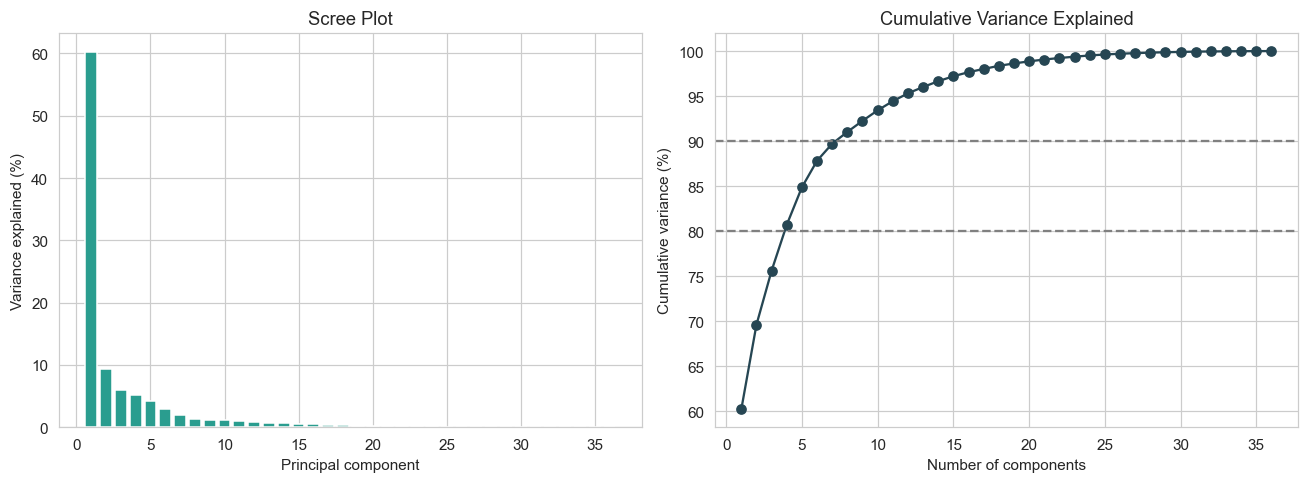

=== Top loadings on PC1 ===
use_ai_work_regularly_pct      0.204
org_provides_training_pct      0.202
increased_revenue_pct          0.199
increased_efficiency_pct       0.199
safeguards_sufficient_pct      0.197
trust_ai_pct                   0.195
org_uses_ai_pct                0.194
relied_not_learning_pct        0.194
couldnt_work_without_ai_pct    0.190
ai_training_pct                0.189
Name: PC1, dtype: float64

=== Top loadings on PC2 ===
contravene_policies_pct        0.299
inappropriate_use_pct          0.297
mistakes_due_ai_pct            0.275
experienced_benefits_pct      -0.273
expect_benefits_pct           -0.268
accept_ai_pct                 -0.264
use_ai_effectively_pct        -0.252
presented_ai_as_own_pct        0.248
top_benefit_pct               -0.235
risks_outweigh_benefits_pct    0.216
Name: PC2, dtype: float64


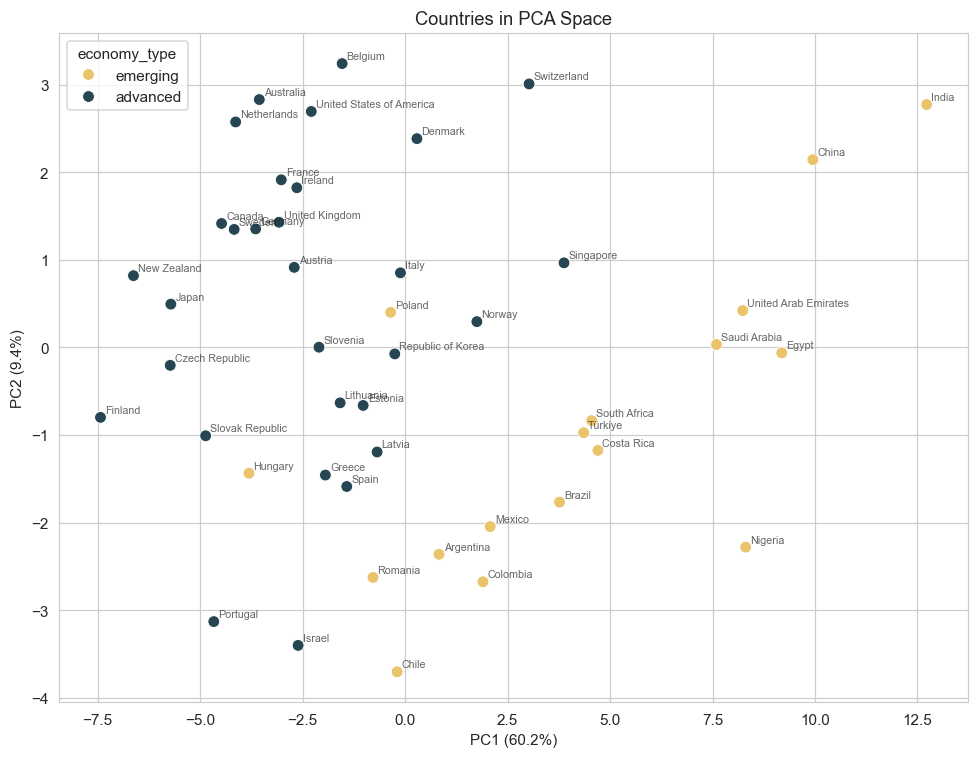


Correlation between PC1 score and trust_ai_pct: 0.909 (sign is arbitrary)


In [40]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = df[pct_cols].dropna()
Xz = StandardScaler().fit_transform(X)
 
pca = PCA().fit(Xz)
evr = pca.explained_variance_ratio_
cum = evr.cumsum()
 
# --- Variance summary ---
print("=== Variance explained ===")
for i in range(5):
    print(f"PC{i+1}: {evr[i]*100:5.1f}%   (cumulative {cum[i]*100:5.1f}%)")
print(f"\nComponents needed for 80% variance: {np.argmax(cum >= 0.80) + 1}")
print(f"Components needed for 90% variance: {np.argmax(cum >= 0.90) + 1}")
print(f"Components with eigenvalue > 1 (Kaiser): {(pca.explained_variance_ > 1).sum()}\n")
 
# --- Scree plot ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
k = np.arange(1, len(evr) + 1)
axes[0].bar(k, evr * 100, color="#2a9d8f")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Variance explained (%)")
axes[0].set_title("Scree Plot")
 
axes[1].plot(k, cum * 100, marker="o", color="#264653")
axes[1].axhline(80, ls="--", color="gray")
axes[1].axhline(90, ls="--", color="gray")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative variance (%)")
axes[1].set_title("Cumulative Variance Explained")
plt.tight_layout()
plt.show()
 
# --- Loadings: which columns drive PC1 and PC2 ---
loadings = pd.DataFrame(pca.components_[:3].T, index=pct_cols,
                        columns=["PC1", "PC2", "PC3"])
 
print("=== Top loadings on PC1 ===")
print(loadings["PC1"].sort_values(key=abs, ascending=False).head(10).round(3))
print("\n=== Top loadings on PC2 ===")
print(loadings["PC2"].sort_values(key=abs, ascending=False).head(10).round(3))
 
# --- Biplot-style view: countries on PC1 vs PC2 ---
scores = pd.DataFrame(pca.transform(Xz)[:, :2], columns=["PC1", "PC2"], index=X.index)
scores["country"] = df.loc[X.index, "country"]
scores["economy_type"] = df.loc[X.index, "economy_type"]
 
fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(data=scores, x="PC1", y="PC2", hue="economy_type",
                palette={"advanced": "#264653", "emerging": "#e9c46a"}, s=60, ax=ax)
for _, r in scores.iterrows():
    ax.annotate(r["country"], (r["PC1"], r["PC2"]), fontsize=7, alpha=0.7,
                xytext=(3, 3), textcoords="offset points")
ax.set_xlabel(f"PC1 ({evr[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({evr[1]*100:.1f}%)")
ax.set_title("Countries in PCA Space")
plt.tight_layout()
plt.show()
 
# --- Does PC1 just reproduce trust? ---
r = np.corrcoef(pca.transform(Xz)[:, 0], df.loc[X.index, "trust_ai_pct"])[0, 1]
print(f"\nCorrelation between PC1 score and trust_ai_pct: {r:.3f} (sign is arbitrary)")
 

Findings:
- PC1 explains 60.2% of the variance -> strong evidence of collinearity. Most of the 35 columns are measuring one "overall AI enthusiasm and adoption" dimension.
- we need 4 components for 80% of the variance and 8 for 90%. So the 35 columns hold roughly 4 to 8 independent dimensions.
- PC1 loads about equally on almost everything. The top loadings, all around 0.19–0.20, include use_ai_work_regularly_pct, increased_efficiency_pct, safeguards_sufficient_pct and trust_ai_pct. This supports earlier observation that positive-disposition countries score high across the board.
- PC2 (9.4%) separates misuse from benefit. contravene_policies_pct, inappropriate_use_pct and mistakes_due_ai_pct sit on one side. experienced_benefits_pct, expect_benefits_pct and accept_ai_pct sit on the other.
- PC1 correlates 0.91 with trust_ai_pct itself. PC1 is essentially trust atp.

=== Variance explained ===
PC1:  59.6%   (cumulative  59.6%)
PC2:   9.6%   (cumulative  69.2%)
PC3:   6.1%   (cumulative  75.3%)
PC4:   5.2%   (cumulative  80.5%)
PC5:   4.3%   (cumulative  84.8%)

Components needed for 80% variance: 4
Components needed for 90% variance: 8
Components with eigenvalue > 1 (Kaiser): 6



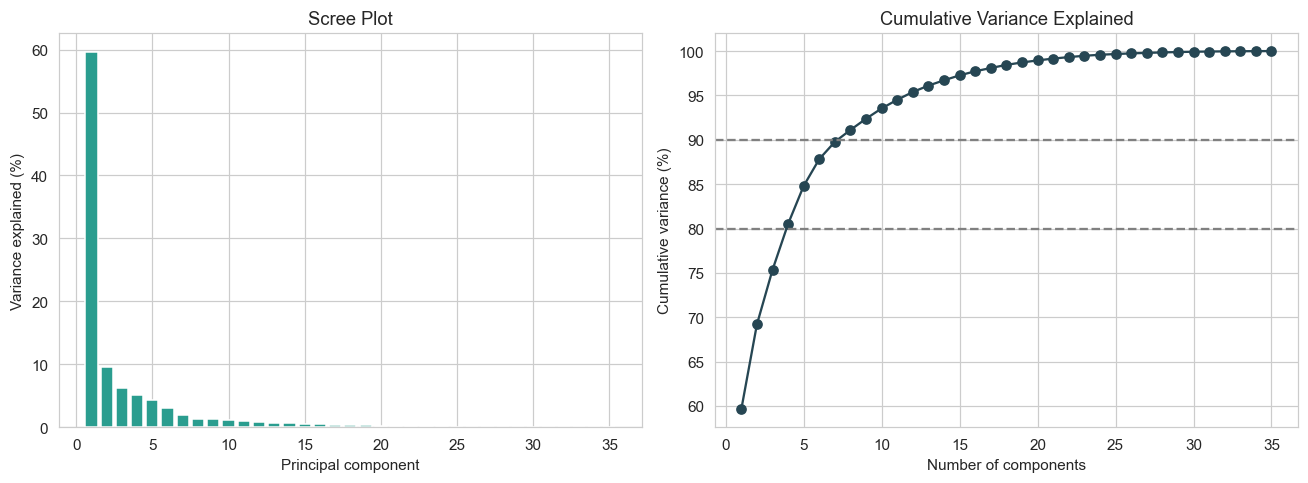

=== Top loadings on PC1 ===
use_ai_work_regularly_pct      0.208
org_provides_training_pct      0.206
increased_revenue_pct          0.203
increased_efficiency_pct       0.202
safeguards_sufficient_pct      0.200
org_uses_ai_pct                0.198
relied_not_learning_pct        0.198
couldnt_work_without_ai_pct    0.194
ai_training_pct                0.193
aware_regulations_pct          0.192
Name: PC1, dtype: float64

=== Top loadings on PC2 ===
contravene_policies_pct        0.294
inappropriate_use_pct          0.292
experienced_benefits_pct      -0.279
expect_benefits_pct           -0.275
mistakes_due_ai_pct            0.271
accept_ai_pct                 -0.270
use_ai_effectively_pct        -0.257
presented_ai_as_own_pct        0.244
top_benefit_pct               -0.241
risks_outweigh_benefits_pct    0.222
Name: PC2, dtype: float64

=== Top loadings on PC3 ===
want_misinfo_laws_pct         0.604
unsure_online_content_pct     0.337
regulation_required_pct       0.313
concerned_left

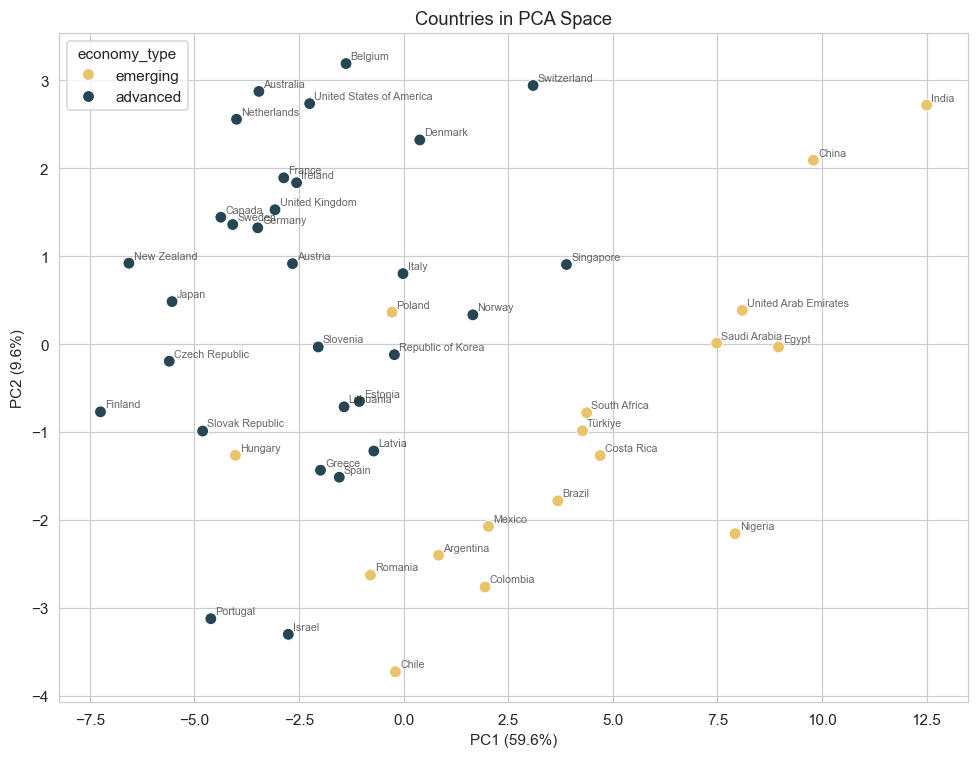


Correlation between PC1 score and trust_ai_pct: 0.900 (sign is arbitrary)


In [41]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

feature_cols = [c for c in pct_cols if c != "trust_ai_pct"]
X = df[feature_cols].dropna()
Xz = StandardScaler().fit_transform(X)
 
pca = PCA().fit(Xz)
evr = pca.explained_variance_ratio_
cum = evr.cumsum()
 
# --- Variance summary ---
print("=== Variance explained ===")
for i in range(5):
    print(f"PC{i+1}: {evr[i]*100:5.1f}%   (cumulative {cum[i]*100:5.1f}%)")
print(f"\nComponents needed for 80% variance: {np.argmax(cum >= 0.80) + 1}")
print(f"Components needed for 90% variance: {np.argmax(cum >= 0.90) + 1}")
print(f"Components with eigenvalue > 1 (Kaiser): {(pca.explained_variance_ > 1).sum()}\n")
 
# --- Scree plot ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
k = np.arange(1, len(evr) + 1)
axes[0].bar(k, evr * 100, color="#2a9d8f")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Variance explained (%)")
axes[0].set_title("Scree Plot")
 
axes[1].plot(k, cum * 100, marker="o", color="#264653")
axes[1].axhline(80, ls="--", color="gray")
axes[1].axhline(90, ls="--", color="gray")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative variance (%)")
axes[1].set_title("Cumulative Variance Explained")
plt.tight_layout()
plt.show()
 
# --- Loadings: which columns drive PC1, PC2 and PC3 ---
loadings = pd.DataFrame(pca.components_[:3].T, index=feature_cols,
                        columns=["PC1", "PC2", "PC3"])

print("=== Top loadings on PC1 ===")
print(loadings["PC1"].sort_values(key=abs, ascending=False).head(10).round(3))
print("\n=== Top loadings on PC2 ===")
print(loadings["PC2"].sort_values(key=abs, ascending=False).head(10).round(3))
print("\n=== Top loadings on PC3 ===")
print(loadings["PC3"].sort_values(key=abs, ascending=False).head(10).round(3))
 
# --- Biplot-style view: countries on PC1 vs PC2 ---
scores = pd.DataFrame(pca.transform(Xz)[:, :2], columns=["PC1", "PC2"], index=X.index)
scores["country"] = df.loc[X.index, "country"]
scores["economy_type"] = df.loc[X.index, "economy_type"]
 
fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(data=scores, x="PC1", y="PC2", hue="economy_type",
                palette={"advanced": "#264653", "emerging": "#e9c46a"}, s=60, ax=ax)
for _, r in scores.iterrows():
    ax.annotate(r["country"], (r["PC1"], r["PC2"]), fontsize=7, alpha=0.7,
                xytext=(3, 3), textcoords="offset points")
ax.set_xlabel(f"PC1 ({evr[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({evr[1]*100:.1f}%)")
ax.set_title("Countries in PCA Space")
plt.tight_layout()
plt.show()
 
# --- Does PC1 just reproduce trust? ---
r = np.corrcoef(pca.transform(Xz)[:, 0], df.loc[X.index, "trust_ai_pct"])[0, 1]
print(f"\nCorrelation between PC1 score and trust_ai_pct: {r:.3f} (sign is arbitrary)")
 

### Q5 Trust vs Accept vs Expected/Experienced benefits

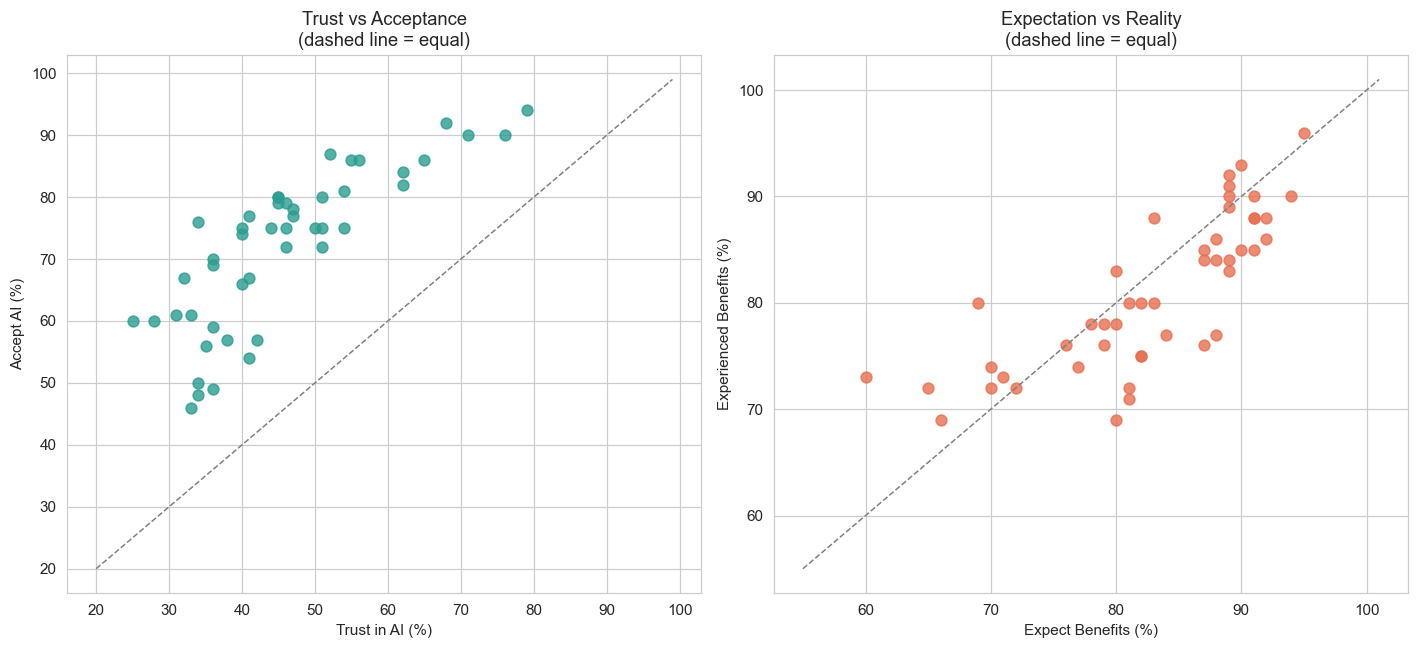

=== Largest Accept > Trust gaps (accept AI despite lower trust) ===
       country  trust_ai_pct  accept_ai_pct  accept_minus_trust
26   Lithuania            34             76                  42
32      Poland            41             77                  36
8     Colombia            45             80                  35
9   Costa Rica            52             87                  35
14     Finland            25             60                  35

=== Largest Expectation > Reality gaps ===
        country  expect_benefits_pct  experienced_benefits_pct  \
28  Netherlands                   80                        69   
32       Poland                   87                        76   
33     Portugal                   88                        77   
3       Belgium                   81                        71   
15       France                   81                        72   

    expect_minus_experience  
28                       11  
32                       11  
33               

In [42]:

# ==================================================================
# Q5 Trust vs Accept vs Expected/Experienced benefits
# ==================================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# Trust vs Accept
axes[0].scatter(df["trust_ai_pct"], df["accept_ai_pct"], color="#2a9d8f", s=50, alpha=0.8)
lims = [df[["trust_ai_pct","accept_ai_pct"]].min().min()-5, df[["trust_ai_pct","accept_ai_pct"]].max().max()+5]
axes[0].plot(lims, lims, "--", color="gray", linewidth=1)
axes[0].set_xlabel("Trust in AI (%)")
axes[0].set_ylabel("Accept AI (%)")
axes[0].set_title("Trust vs Acceptance\n(dashed line = equal)")

# Expected vs Experienced benefits
axes[1].scatter(df["expect_benefits_pct"], df["experienced_benefits_pct"], color="#e76f51", s=50, alpha=0.8)
lims2 = [df[["expect_benefits_pct","experienced_benefits_pct"]].min().min()-5,
         df[["expect_benefits_pct","experienced_benefits_pct"]].max().max()+5]
axes[1].plot(lims2, lims2, "--", color="gray", linewidth=1)
axes[1].set_xlabel("Expect Benefits (%)")
axes[1].set_ylabel("Experienced Benefits (%)")
axes[1].set_title("Expectation vs Reality\n(dashed line = equal)")

plt.tight_layout()
plt.show()

df["accept_minus_trust"] = df["accept_ai_pct"] - df["trust_ai_pct"]
df["expect_minus_experience"] = df["expect_benefits_pct"] - df["experienced_benefits_pct"]
print("=== Largest Accept > Trust gaps (accept AI despite lower trust) ===")
print(df.nlargest(5, "accept_minus_trust")[["country","trust_ai_pct","accept_ai_pct","accept_minus_trust"]])
print()
print("=== Largest Expectation > Reality gaps ===")
print(df.nlargest(5, "expect_minus_experience")[["country","expect_benefits_pct","experienced_benefits_pct","expect_minus_experience"]])
print()

Findings:
- every single country sits above the diagonal in both panels. 
- acceptance is universally higher than trust, meaning people use/accept AI even when they don't fully trust it. I call tis duality of men.
- experienced benefits mostly exceed expected benefits, meaning AI is broadly outperforming expectations rather than disappointing people.

### Q6 Sentiment labeling validation

C:\Users\welth\AppData\Local\Temp\ipykernel_62664\4278860914.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="sentiment", y="trust_ai_pct", order=sentiment_order, ax=axes[1], palette="Blues")


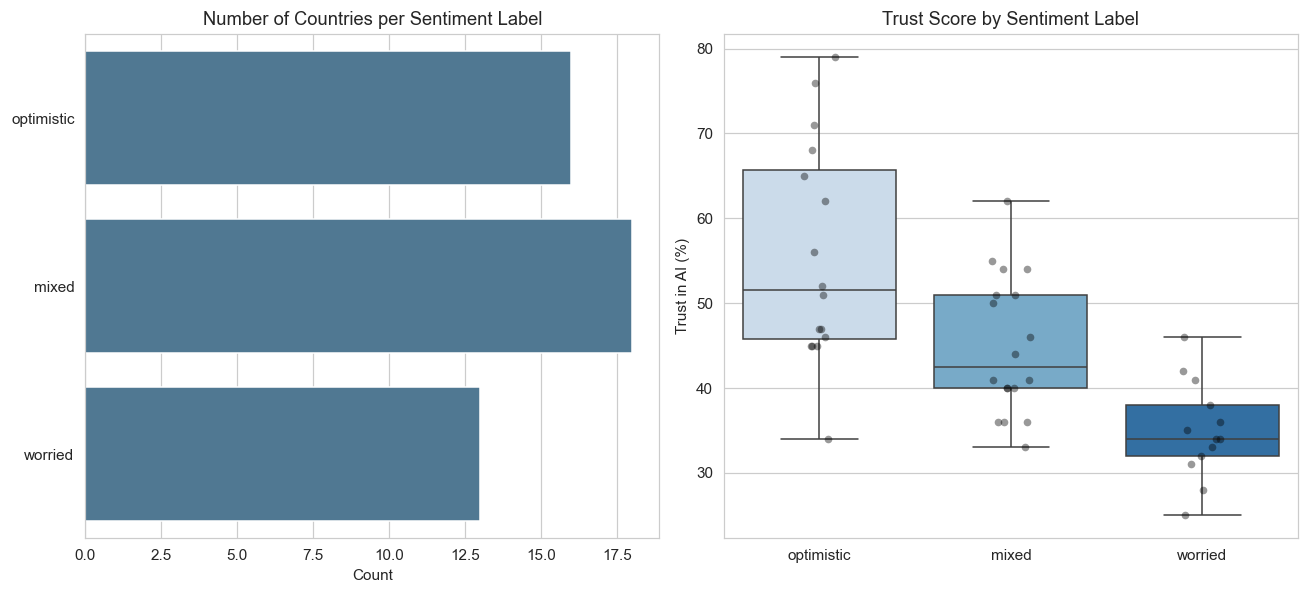

In [43]:

# ==================================================================
# Q6 Sentiment category validation
# ==================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

sentiment_order = df.groupby("sentiment")["trust_ai_pct"].median().sort_values(ascending=False).index
sns.countplot(data=df, y="sentiment", order=sentiment_order, ax=axes[0], color="#457b9d")
axes[0].set_title("Number of Countries per Sentiment Label")
axes[0].set_xlabel("Count")
axes[0].set_ylabel("")

sns.boxplot(data=df, x="sentiment", y="trust_ai_pct", order=sentiment_order, ax=axes[1], palette="Blues")
sns.stripplot(data=df, x="sentiment", y="trust_ai_pct", order=sentiment_order, ax=axes[1], color="black", alpha=0.4)
axes[1].set_title("Trust Score by Sentiment Label")
axes[1].set_xlabel("")
axes[1].set_ylabel("Trust in AI (%)")

plt.tight_layout()
plt.show()

Findings:
- the difference between the groups is fairly substantial 
- but generally more positive sentiment toward AI is associated with higher reported trust

### Q7 "Problematic AI use" composite vs trust

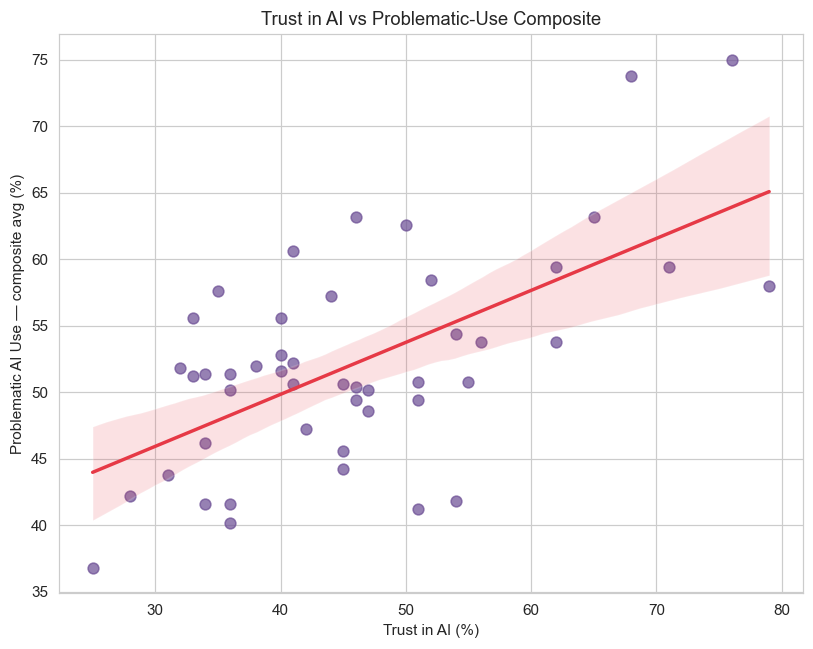

=== Misuse composite vs trust: Pearson r = 0.614 ===
                 country  trust_ai_pct  misuse_composite
19                 India            76              75.0
7                  China            68              73.8
42           Switzerland            46              63.2
44  United Arab Emirates            65              63.2
36             Singapore            50              62.6



In [44]:

# ==================================================================
# Q7 "Problematic AI use" composite vs trust
# ==================================================================
misuse_cols = ["inappropriate_use_pct", "mistakes_due_ai_pct", "contravene_policies_pct",
               "relied_no_eval_pct", "presented_ai_as_own_pct"]
df["misuse_composite"] = df[misuse_cols].mean(axis=1)

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.regplot(data=df, x="trust_ai_pct", y="misuse_composite", ax=ax,
            scatter_kws={"color": "#6a4c93", "alpha": 0.7, "s": 50},
            line_kws={"color": "#e63946"})
ax.set_title("Trust in AI vs Problematic-Use Composite")
ax.set_xlabel("Trust in AI (%)")
ax.set_ylabel("Problematic AI Use — composite avg (%)")
plt.tight_layout()
plt.show()

r = df["trust_ai_pct"].corr(df["misuse_composite"])
print(f"=== Misuse composite vs trust: Pearson r = {r:.3f} ===")
print(df.nlargest(5, "misuse_composite")[["country","trust_ai_pct","misuse_composite"]])
print()

More findings:
- higher-trust countries report more problematic AI use, not less (r = 0.61). 
- high trust, without proper safeguard, may translate into more careless use (over-trust), rather than trust always being a good thing.

### Q8 GDP per capita vs trust

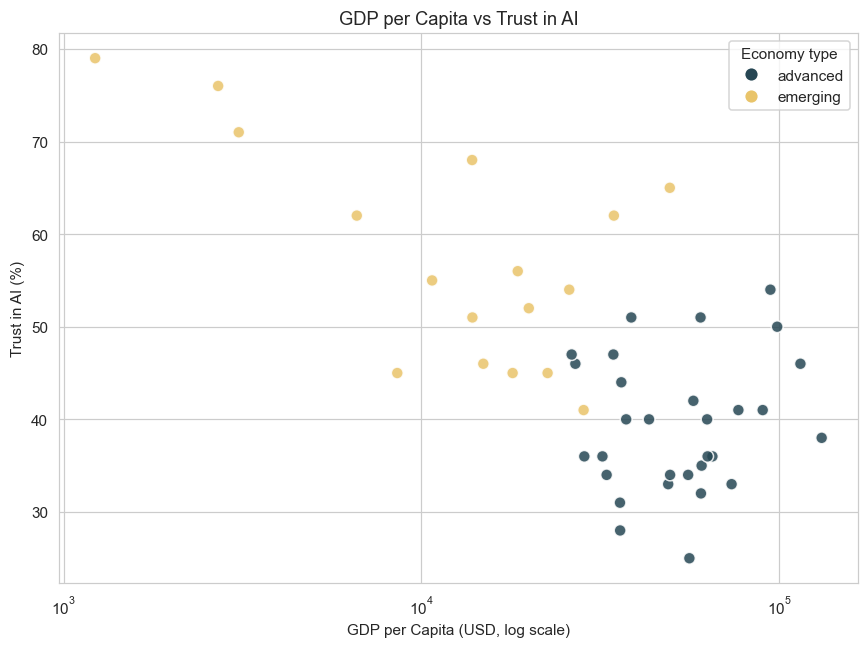

=== GDP per capita vs trust: Spearman r = -0.514 ===


In [45]:

# ==================================================================
# Q8 GDP per capita vs trust
# ==================================================================
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(df["gdp_per_capita_usd"], df["trust_ai_pct"],
                 c=df["economy_type"].map({"advanced": "#264653", "emerging": "#e9c46a"}),
                 s=60, alpha=0.85, edgecolor="white")
ax.set_xscale("log")
ax.set_xlabel("GDP per Capita (USD, log scale)")
ax.set_ylabel("Trust in AI (%)")
ax.set_title("GDP per Capita vs Trust in AI")
handles = [plt.Line2D([0],[0], marker='o', color='w', markerfacecolor=c, markersize=9, label=l)
           for l, c in [("advanced", "#264653"), ("emerging", "#e9c46a")]]
ax.legend(handles=handles, title="Economy type")
plt.tight_layout()
plt.show()

r_gdp = df["gdp_per_capita_usd"].corr(df["trust_ai_pct"], method="spearman")
print(f"=== GDP per capita vs trust: Spearman r = {r_gdp:.3f} ===")

Findings:
- negative relationship (Spearman r = -0.51), meaning trust falls fairly steadily as GDP per capita rises.

### Q9 Benefits → Trust

In [46]:
# ==================================================================
# Q9 Benefits → Trust
# ==================================================================

benefit_cols = [
    "expect_benefits_pct",
    "experienced_benefits_pct"
]

for col in benefit_cols:
    r = df["trust_ai_pct"].corr(df[col], method="spearman")
    print(f"{col} vs trust: Spearman r = {r:.3f}")

expect_benefits_pct vs trust: Spearman r = 0.692
experienced_benefits_pct vs trust: Spearman r = 0.739


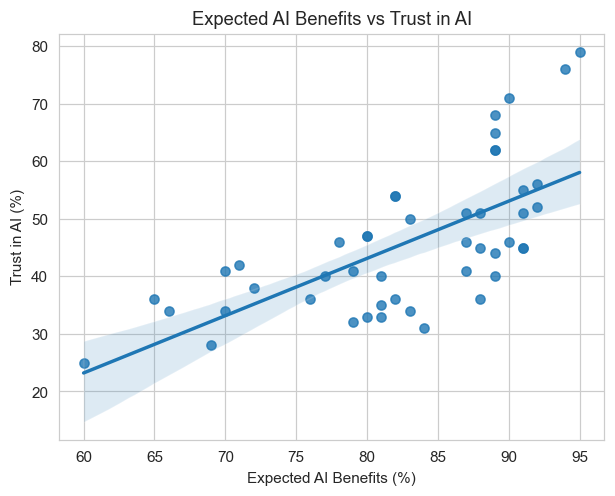

In [47]:
sns.regplot(
    data=df,
    x="expect_benefits_pct",
    y="trust_ai_pct"
)

plt.xlabel("Expected AI Benefits (%)")
plt.ylabel("Trust in AI (%)")
plt.title("Expected AI Benefits vs Trust in AI")
plt.show()

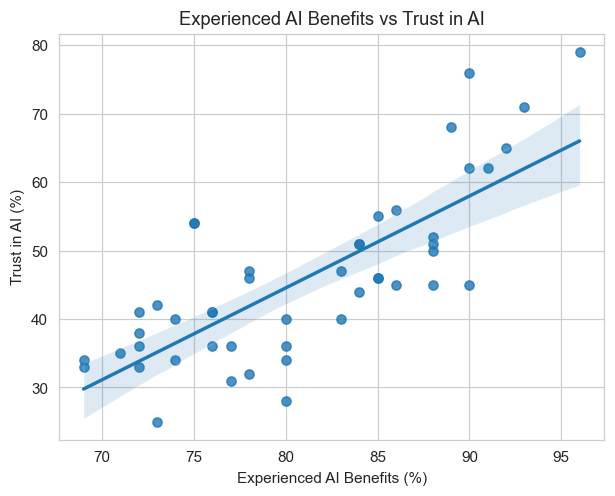

In [48]:
sns.regplot(
    data=df,
    x="experienced_benefits_pct",
    y="trust_ai_pct"
)

plt.xlabel("Experienced AI Benefits (%)")
plt.ylabel("Trust in AI (%)")
plt.title("Experienced AI Benefits vs Trust in AI")
plt.show()

Findings:
- positive relationship. expect_benefits_pct vs trust: Spearman r = 0.692 and experienced_benefits_pct vs trust: Spearman r = 0.739 means yes to both question


## Second Dataset - Trend

### Q10 Has the perception that AI benefits outweigh drawbacks improved from 2023 to 2024?

In [49]:
from pathlib import Path
# ==================================================================
# Q10 Has the perception that AI benefits outweigh drawbacks improved from 2023 to 2024?
# ==================================================================
from scipy import stats

df2 = pd.read_csv(DATA_DIR / "ai_benefit_perception_trend.csv")

# China and Switzerland have no 2023 value, so they can't have a change score
n_total = len(df2)
t = df2.dropna(subset=["change_2023_2024_pp"]).copy()
print(f"Countries in file: {n_total} | with both years: {len(t)} "
      f"(excluded: {', '.join(df2.loc[df2['change_2023_2024_pp'].isna(), 'country'])})\n")


Countries in file: 32 | with both years: 30 (excluded: China, Switzerland)



In [50]:
# --- 1. Average change ---
mean_chg = t["change_2023_2024_pp"].mean()
median_chg = t["change_2023_2024_pp"].median()
print("=== Average change (percentage points) ===")
print(f"Mean:   {mean_chg:+.2f} pp")
print(f"Median: {median_chg:+.2f} pp")
print(f"2023 mean: {t['benefit_gt_drawback_2023_pct'].mean():.1f}%  ->  "
      f"2024 mean: {t['benefit_gt_drawback_2024_pct'].mean():.1f}%\n")

=== Average change (percentage points) ===
Mean:   +0.47 pp
Median: +1.50 pp
2023 mean: 54.1%  ->  2024 mean: 54.6%



Findings:
- The average change is small: +0.47 pp (median +1.5 pp). 
- The 30-country mean moves from 54.1% to 54.6%.

In [51]:

# --- 2. Increasing vs decreasing ---
up = (t["change_2023_2024_pp"] > 0).sum()
down = (t["change_2023_2024_pp"] < 0).sum()
same = (t["change_2023_2024_pp"] == 0).sum()
print("=== Direction of change ===")
print(f"Increased: {up} | Decreased: {down} | Unchanged: {same}\n")


=== Direction of change ===
Increased: 17 | Decreased: 9 | Unchanged: 4



Finding:
- 17 countries rose, 9 fell and 4 were unchanged, so more countries improved than declined.

In [52]:

# --- 3. Biggest movers ---
cols = ["country", "benefit_gt_drawback_2023_pct",
        "benefit_gt_drawback_2024_pct", "change_2023_2024_pp"]
print("=== Top 5 increases ===")
print(t.nlargest(5, "change_2023_2024_pp")[cols].to_string(index=False))
print("\n=== Top 5 decreases ===")
print(t.nsmallest(5, "change_2023_2024_pp")[cols].to_string(index=False))


=== Top 5 increases ===
    country  benefit_gt_drawback_2023_pct  benefit_gt_drawback_2024_pct  change_2023_2024_pp
    Germany                          42.0                            47                  5.0
    Ireland                          40.0                            45                  5.0
    Hungary                          47.0                            51                  4.0
New Zealand                          44.0                            48                  4.0
  Australia                          40.0                            44                  4.0

=== Top 5 decreases ===
    country  benefit_gt_drawback_2023_pct  benefit_gt_drawback_2024_pct  change_2023_2024_pp
     Brazil                          64.0                            56                 -8.0
Netherlands                          43.0                            36                 -7.0
   Malaysia                          69.0                            63                 -6.0
      Japan          

Finding:
- Biggest increases: Germany and Ireland (+5), then Hungary, New Zealand and Australia (+4).
- Biggest decreases: Brazil (−8), Netherlands (−7), Malaysia (−6), Japan (−4) and Mexico (−3).

In [53]:

# --- 4. Is the average change statistically different from zero? ---
# Wilcoxon signed-rank is safer than a t-test with this few countries and
# integer-rounded changes. Zero changes are dropped by default.
w_stat, w_p = stats.wilcoxon(t["change_2023_2024_pp"], zero_method="wilcox")
t_stat, t_p = stats.ttest_1samp(t["change_2023_2024_pp"], 0)
print("\n=== Is the average change different from zero? ===")
print(f"Wilcoxon signed-rank: p = {w_p:.4f}")
print(f"One-sample t-test:    p = {t_p:.4f}")
print("Note: small sample (n≈30) and survey figures are rounded, so treat as indicative.\n")



=== Is the average change different from zero? ===
Wilcoxon signed-rank: p = 0.3584
One-sample t-test:    p = 0.4797
Note: small sample (n≈30) and survey figures are rounded, so treat as indicative.



Finding:
- The change is not statistically significant (Wilcoxon p = 0.36, t-test p = 0.48).

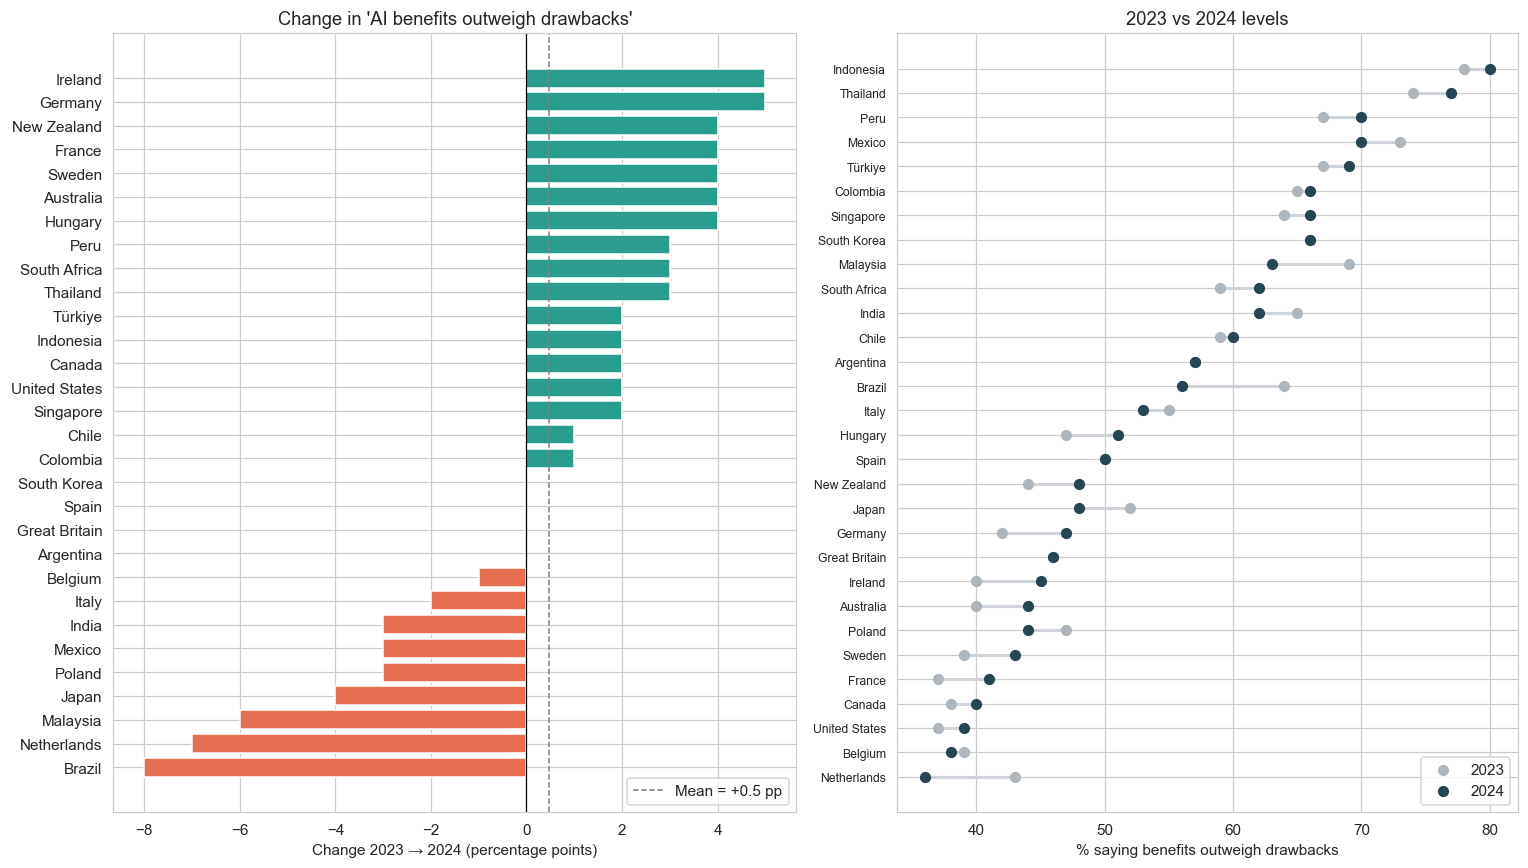

In [54]:

# --- 5. Charts ---
ts = t.sort_values("change_2023_2024_pp")
colors = np.where(ts["change_2023_2024_pp"] > 0, "#2a9d8f",
         np.where(ts["change_2023_2024_pp"] < 0, "#e76f51", "#adb5bd"))

fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1.1, 1]})

# Left: change by country
axes[0].barh(ts["country"], ts["change_2023_2024_pp"], color=colors)
axes[0].axvline(0, color="black", lw=0.8)
axes[0].axvline(mean_chg, color="gray", ls="--", lw=1, label=f"Mean = {mean_chg:+.1f} pp")
axes[0].set_xlabel("Change 2023 → 2024 (percentage points)")
axes[0].set_title("Change in 'AI benefits outweigh drawbacks'")
axes[0].legend(loc="lower right")

# Right: dumbbell 2023 vs 2024
td = t.sort_values("benefit_gt_drawback_2024_pct")
y = np.arange(len(td))
axes[1].hlines(y, td["benefit_gt_drawback_2023_pct"], td["benefit_gt_drawback_2024_pct"],
               color="#ced4da", lw=2)
axes[1].scatter(td["benefit_gt_drawback_2023_pct"], y, color="#adb5bd", s=40, label="2023", zorder=3)
axes[1].scatter(td["benefit_gt_drawback_2024_pct"], y, color="#264653", s=40, label="2024", zorder=3)
axes[1].set_yticks(y)
axes[1].set_yticklabels(td["country"], fontsize=8)
axes[1].set_xlabel("% saying benefits outweigh drawbacks")
axes[1].set_title("2023 vs 2024 levels")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

Finding:
- there is a slight improvement, but not detectable. The direction leans positive (17 up vs 9 down), but the average shift is under one point and could easily be noise. 
- The median is higher than the mean because a few large drops (Brazil, Netherlands, Malaysia) pull the mean down.
- The pattern by economy type is worth a follow-up. Most of the larger increases are in advanced economies (Germany, Ireland, Australia, New Zealand), while the largest drops include emerging ones (Brazil, Malaysia).